# 1. Setup: load original + all three transform results

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from itertools import combinations

CLASSES = ["call", "dislike", "fist", "four", "like"]
PROB_COLS = [f"prob_{c}" for c in CLASSES]

files = {
    "original": "/Users/Jakub/Desktop/AI-VIS/phase1-Ai/split_preprocess-train/base results and setup/test_set_merged.csv",
    "flipped_upside_down": "/Users/Jakub/Downloads/test_results_flipped_upside_down.csv",
    "black_and_white": "/Users/Jakub/Downloads/test_results_black_and_white.csv",
    "brightness_raised": "/Users/Jakub/Downloads/test_results_brightness_raised.csv",
}

data = {}
for name, path in files.items():
    d = pd.read_csv(path)
    probs = d[PROB_COLS].values
    sorted_probs = np.sort(probs, axis=1)
    d["margin"] = sorted_probs[:, -1] - sorted_probs[:, -2]
    data[name] = d
    print(name, "accuracy:", d["correct"].mean())

original accuracy: 0.871
flipped_upside_down accuracy: 0.257
black_and_white accuracy: 0.734
brightness_raised accuracy: 0.714


# 2. Prediction distribution per condition (checks for mode collapse)

/var/folders/hx/pkkyjw395tng44gg777djtcc0000gp/T/ipykernel_36681/2570710075.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(CLASSES, rotation=45)
/var/folders/hx/pkkyjw395tng44gg777djtcc0000gp/T/ipykernel_36681/2570710075.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(CLASSES, rotation=45)
/var/folders/hx/pkkyjw395tng44gg777djtcc0000gp/T/ipykernel_36681/2570710075.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(CLASSES, rotation=45)
/var/folders/hx/pkkyjw395tng44gg777djtcc0000gp/T/ipykernel_36681/2570710075.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(CLASSES, r

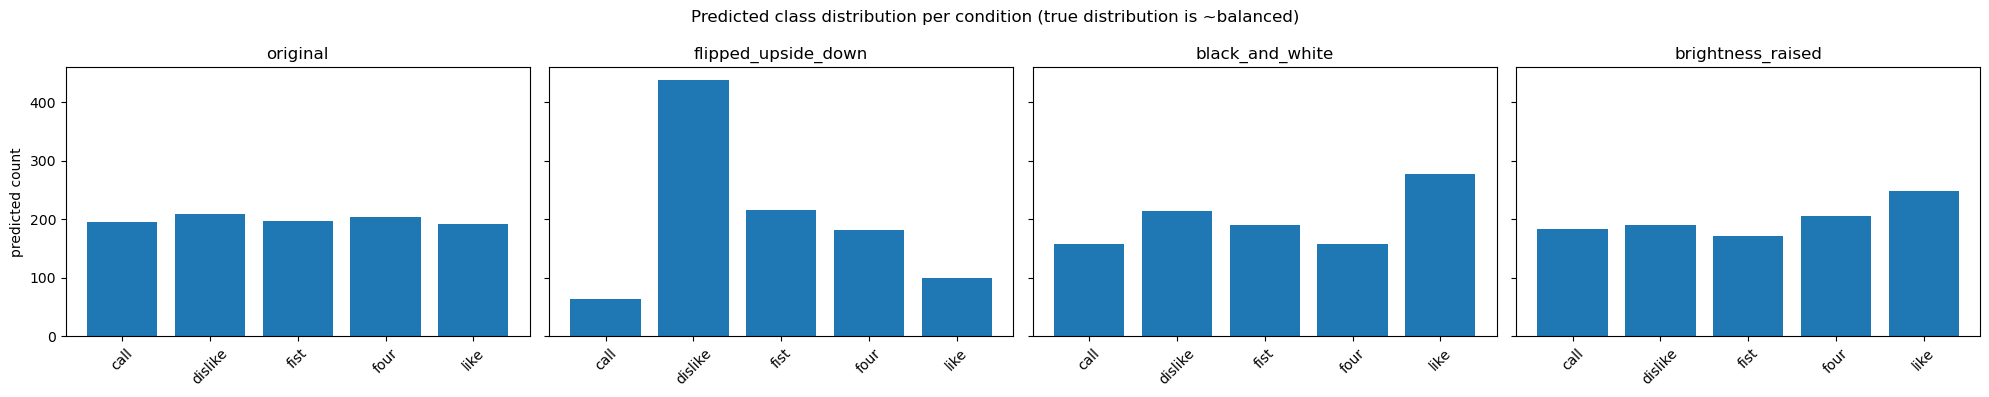

In [3]:
fig, axes = plt.subplots(1, len(data), figsize=(5 * len(data), 4), sharey=True)
for ax, (name, d) in zip(axes, data.items()):
    counts = d["pred_label"].value_counts().reindex(CLASSES).fillna(0)
    ax.bar(CLASSES, counts)
    ax.set_title(name)
    ax.set_xticklabels(CLASSES, rotation=45)
axes[0].set_ylabel("predicted count")
plt.suptitle("Predicted class distribution per condition (true distribution is ~balanced)")
plt.tight_layout()
plt.show()

# 3. Confusion matrix per condition, side by side

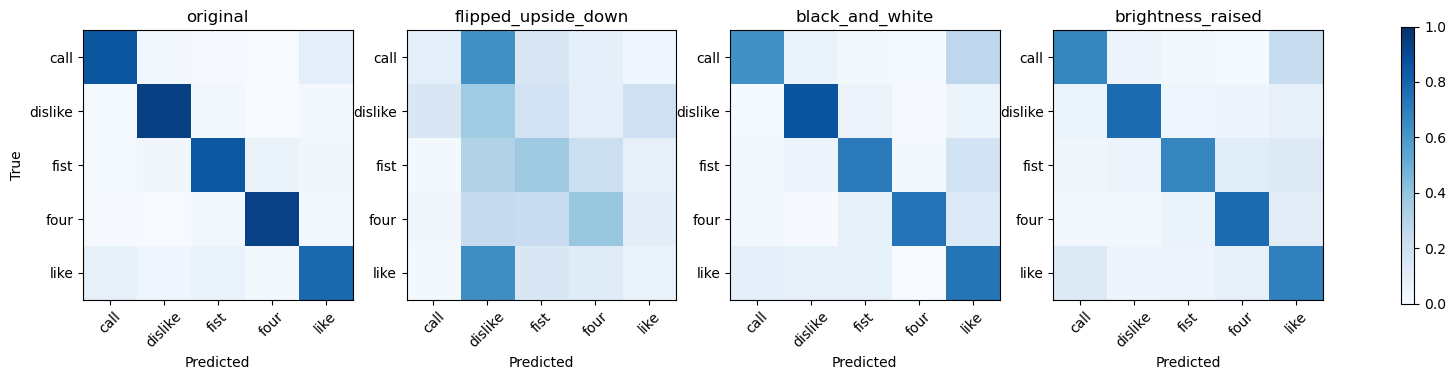

In [4]:
fig, axes = plt.subplots(1, len(data), figsize=(5 * len(data), 4.5))
for ax, (name, d) in zip(axes, data.items()):
    cm = confusion_matrix(d["true_label"], d["pred_label"], labels=CLASSES, normalize="true")
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(CLASSES)))
    ax.set_yticks(range(len(CLASSES)))
    ax.set_xticklabels(CLASSES, rotation=45)
    ax.set_yticklabels(CLASSES)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
axes[0].set_ylabel("True")
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

# 4. Confidence margin: correct vs incorrect, per condition

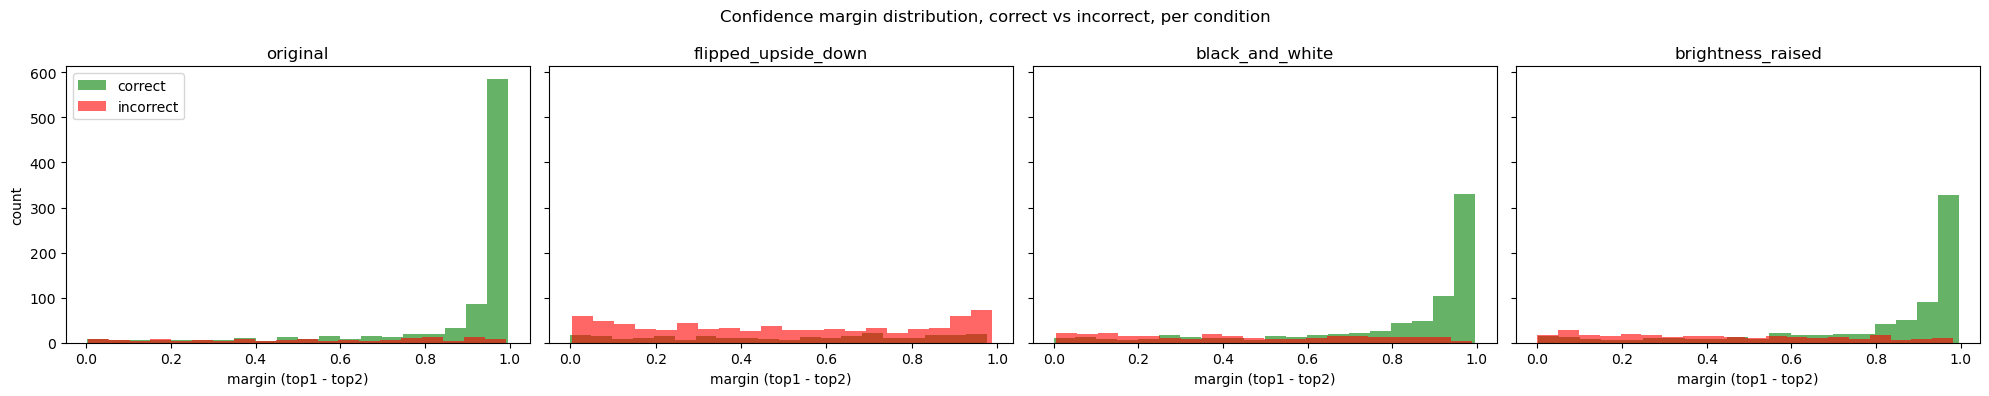

In [5]:
fig, axes = plt.subplots(1, len(data), figsize=(5 * len(data), 4), sharey=True)
for ax, (name, d) in zip(axes, data.items()):
    ax.hist(d.loc[d["correct"], "margin"], bins=20, alpha=0.6, label="correct", color="green")
    ax.hist(d.loc[~d["correct"], "margin"], bins=20, alpha=0.6, label="incorrect", color="red")
    ax.set_title(name)
    ax.set_xlabel("margin (top1 - top2)")
axes[0].set_ylabel("count")
axes[0].legend()
plt.suptitle("Confidence margin distribution, correct vs incorrect, per condition")
plt.tight_layout()
plt.show()

# 5. Error overlap across the three transforms (upset-style bar chart)

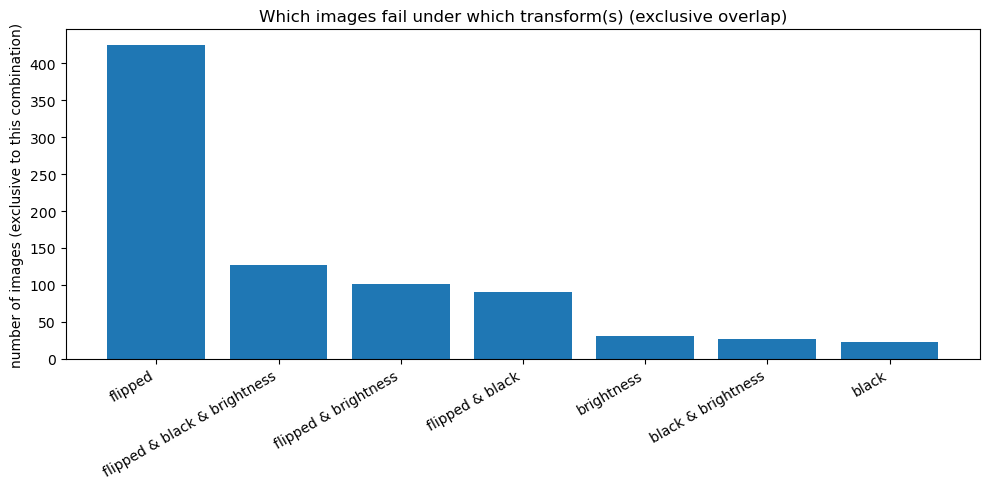

originally-correct images broken by transform:
flipped_upside_down 634
black_and_white 163
brightness_raised 178


In [6]:
transform_names = ["flipped_upside_down", "black_and_white", "brightness_raised"]

merged = data["original"][["id", "correct"]].rename(columns={"correct": "correct_original"})
for name in transform_names:
    merged = merged.merge(
        data[name][["id", "correct"]].rename(columns={"correct": f"correct_{name}"}),
        on="id"
    )

incorrect_sets = {name: set(merged.loc[~merged[f"correct_{name}"], "id"]) for name in transform_names}

all_combos = []
for r in range(1, len(transform_names) + 1):
    for combo in combinations(transform_names, r):
        ids_in_all = set.intersection(*[incorrect_sets[c] for c in combo])
        ids_in_others = set.union(*[incorrect_sets[o] for o in transform_names if o not in combo]) if r < len(transform_names) else set()
        exclusive = ids_in_all - ids_in_others
        all_combos.append((" & ".join(c.split("_")[0] for c in combo), len(exclusive)))

all_combos.sort(key=lambda x: -x[1])
labels, counts = zip(*all_combos)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(labels, counts)
ax.set_ylabel("number of images (exclusive to this combination)")
ax.set_title("Which images fail under which transform(s) (exclusive overlap)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

print("originally-correct images broken by transform:")
for name in transform_names:
    newly_broken = merged[merged["correct_original"] & ~merged[f"correct_{name}"]]
    print(name, len(newly_broken))

# 6. Original margin vs robustness to each transform

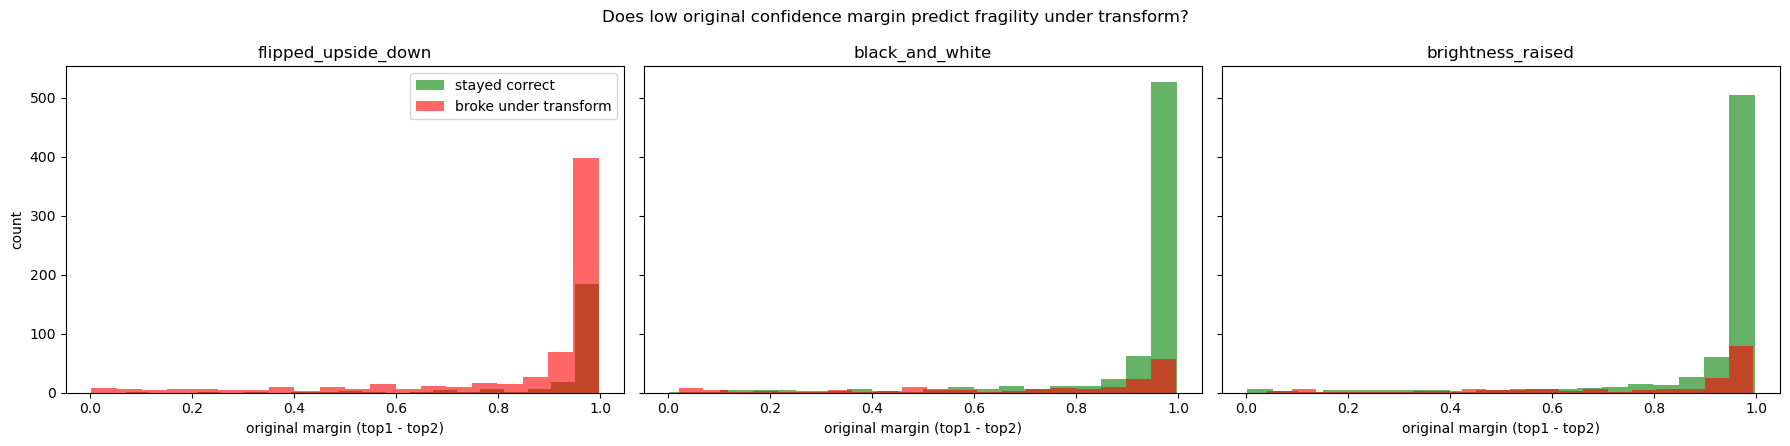

In [7]:
orig_margin = data["original"][["id", "margin"]].rename(columns={"margin": "original_margin"})
merged2 = merged.merge(orig_margin, on="id")

fig, axes = plt.subplots(1, len(transform_names), figsize=(6 * len(transform_names), 4.5), sharey=True)
for ax, name in zip(axes, transform_names):
    still_correct = merged2[merged2["correct_original"] & merged2[f"correct_{name}"]]
    broke = merged2[merged2["correct_original"] & ~merged2[f"correct_{name}"]]
    ax.hist(still_correct["original_margin"], bins=20, alpha=0.6, label="stayed correct", color="green")
    ax.hist(broke["original_margin"], bins=20, alpha=0.6, label="broke under transform", color="red")
    ax.set_title(name)
    ax.set_xlabel("original margin (top1 - top2)")
axes[0].set_ylabel("count")
axes[0].legend()
plt.suptitle("Does low original confidence margin predict fragility under transform?")
plt.tight_layout()
plt.show()